# VarreSP | Onde verificar a falta de varrição na próxima semana?

**Observatório de Bairro · FIAP · Global Solution 2026.2**  
Data Science & Statistical Computing · São Paulo, SP

Quem caminha pela Lapa tem interesse em que a zeladoria detecte falhas recorrentes antes que mais moradores precisem abrir um chamado. O protótipo permite à equipe de supervisão escolher distritos para vistoria a partir das reclamações registradas. A Lapa serve como caso de leitura; o painel cobre os 96 distritos para permitir a comparação entre territórios.

**Pergunta 1.** Ao início de cada segunda-feira, quantos pedidos de varrição serão registrados nesse distrito até domingo? O alvo numérico é a contagem semanal publicada no SP156.

**Pergunta 2.** Qual a probabilidade de o volume atingir o patamar de alta demanda definido no histórico de treino? O alvo vale 1 quando a contagem alcança esse patamar e 0 nos demais casos.

**Decisão a avaliar.** Supondo capacidade para revisar três distritos por semana, quantos dos locais priorizados de fato terão alta demanda? Esse orçamento é uma hipótese de planejamento. Medimos o acerto retrospectivo e a cobertura territorial. Validar a melhoria da limpeza requer vistorias em campo.

## 1. Origem e construção da amostra

Fonte primária: Prefeitura de São Paulo, **Dados do SP156**, quatro arquivos trimestrais de 2025. Cada linha original é um registro publicado. O filtro é a igualdade exata do campo Serviço com **Fazer reclamação de falta de varrição**. Pedidos de retirada de sacos de varrição e de coleta domiciliar são outros serviços.

| Arquivo oficial | Linhas lidas | Do serviço | Sem distrito | Dias com publicação de aberturas¹ |
|---|---:|---:|---:|---:|
| [Dados do SP156 - 1º TRI 2025](https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource/7c5aeb58-2cad-40ba-9e9e-af1c17cc5070/download/arquivo-final-1-trim-25.csv) | 1.048.575 | 7.111 | 1 | 90 |
| [Dados do SP156 - 2º TRI 2025](https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource/f5df7f4a-d614-4f85-b4a0-263ec9370cd9/download/arquivo-final-2-trim-25.csv) | 589.980 | 6.744 | 4 | 91 |
| [Dados do SP156 - 3º TRI 2025](https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource/3b1d2648-d586-40c8-819c-24fbb8005343/download/arquivo-final-3-trim-25.csv) | 501.685 | 9.526 | 9 | 92 |
| [Dados do SP156 - 4º TRI 2025](https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource/d3a98097-8128-45d4-b8fe-21874b81c971/download/arquivo-final-4-trim-25.csv) | 479.701 | 9.195 | 9 | 92 |

¹ Datas de abertura distintas em todos os serviços. Houve registros em todos os dias dos quatro trimestres. O primeiro arquivo tem exatamente 1.048.575 registros, o que recomenda cautela quanto à completude da publicação. Cobertura de datas não garante cobertura de todos os chamados.

Descartamos 23 chamados sem distrito e as semanas incompletas nas pontas do ano. A base anexa soma **32.021 pedidos**. Cada linha combina um distrito e uma semana completa de segunda a domingo. Em semanas cobertas pelo arquivo, uma combinação sem registro recebe zero pedidos publicados. A fonte não oferece neste recorte uma chave pública de atendimento para confirmar duplicatas; duas solicitações com mesmo serviço, distrito e data podem ser legítimas. O CSV agregado preserva ambas. Nenhum endereço individual integra a análise.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, precision_score, recall_score, f1_score)

dados = pd.read_csv(Path("varricao_sp156.csv"), parse_dates=["semana"])
chave = ["distrito", "semana"]
assert not dados.isna().any().any(), "Há campos ausentes no painel semanal."
assert not dados.duplicated(chave).any(), "Há mais de uma linha para o mesmo distrito e semana."
assert pd.api.types.is_integer_dtype(dados.pedidos) and dados.pedidos.ge(0).all(), "Contagem inválida."
calendario = pd.date_range("2025-01-06", "2025-12-22", freq="W-MON")
distritos = sorted(dados.distrito.unique())
assert len(distritos) == 96, "O recorte deve conter os 96 distritos."
esperado = pd.MultiIndex.from_product([distritos, calendario], names=chave)
dados = dados.sort_values(chave).reset_index(drop=True)
assert dados.set_index(chave).index.equals(esperado), "Confira semanas ausentes ou fora do recorte."
print(f"{len(dados)} observações | {dados.pedidos.sum()} pedidos | {len(distritos)} distritos")
display(dados.pedidos.describe().to_frame("Pedidos por distrito e semana").round(2))

4896 observações | 32021 pedidos | 96 distritos


,Pedidos por distrito e semana
count,4896.00
mean,6.54
std,9.19
min,0.00
25%,3.00
50%,5.00
75%,8.00
max,173.00


## 2. Como simular uma previsão feita na segunda-feira

Cada variável de entrada depende apenas das semanas já encerradas no mesmo distrito. Usamos a última contagem, a média móvel de quatro semanas e a média de longo prazo disponível até a véspera. Esta última ajuda a representar o nível habitual de cada território sem usar a média anual futura. As primeiras quatro semanas formam o histórico inicial.

Treino até agosto, validação em setembro e teste a partir de outubro, em blocos inteiros de semanas. O treino determina os coeficientes, a escala e o patamar de alta demanda. A validação determina o ponto de corte das probabilidades. O teste fica reservado para a avaliação final. Durante o teste, cada nova semana pode usar as contagens já encerradas, como em uma operação semanal com dados disponíveis sem atraso.

In [2]:
por_distrito = dados.groupby("distrito", sort=False)["pedidos"]
dados["anterior"] = por_distrito.shift(1)
historico = dados.groupby("distrito", sort=False)["anterior"]
dados["media_4"] = historico.transform(lambda x: x.rolling(4, min_periods=4).mean())
dados["media_historica"] = historico.transform(lambda x: x.expanding().mean())
atributos = ["anterior", "media_4", "media_historica"]
base = dados.dropna(subset=atributos).copy()
treino = base.loc[base.semana < "2025-09-01"].copy()
validacao = base.loc[base.semana.between("2025-09-01", "2025-09-29")].copy()
teste = base.loc[base.semana >= "2025-10-06"].copy()
assert treino.semana.max() < validacao.semana.min() <= validacao.semana.max() < teste.semana.min()
assert len(treino) + len(validacao) + len(teste) == len(base), "Há semanas fora dos blocos."
limite = int(treino.pedidos.quantile(0.75, interpolation="higher"))
def alta(quadro):
    return quadro.pedidos.ge(limite).astype(int)

resumo = []
for nome, parte in [("Treino", treino), ("Validação", validacao), ("Teste", teste)]:
    resumo.append([nome, parte.semana.min().date(), parte.semana.max().date(),
                   parte.semana.nunique(), len(parte), alta(parte).sum(), alta(parte).mean()])
display(pd.DataFrame(resumo, columns=["Bloco","Primeira segunda","Última segunda",
             "Semanas","Linhas","Casos de alta","Proporção"]).round(3))
print(f"Alta demanda = pelo menos {limite} pedidos publicados por distrito na semana.")

,Bloco,Primeira segunda,Última segunda,Semanas,Linhas,Casos de alta,Proporção
0,Treino,2025-02-03,2025-08-25,30,2880,873,0.303
1,Validação,2025-09-01,2025-09-29,5,480,260,0.542
2,Teste,2025-10-06,2025-12-22,12,1152,395,0.343


Alta demanda = pelo menos 7 pedidos publicados por distrito na semana.


## 3. Regressão linear | volume semanal

Ajustamos mínimos quadrados ordinários às três entradas históricas. Aplicamos piso zero às previsões contínuas porque a contagem não pode ser negativa. Mantemos as casas decimais para medir o erro. A referência operacional já disponível seria repetir a última semana ou usar a média das quatro anteriores.

In [3]:
linear = make_pipeline(StandardScaler(), LinearRegression())
linear.fit(treino[atributos], treino.pedidos)
teste["volume_previsto"] = np.maximum(0, linear.predict(teste[atributos]))
comparacao = {}
for nome, valores in {"Última semana": teste.anterior, "Média de 4 semanas": teste.media_4,
                     "Regressão linear": teste.volume_previsto}.items():
    comparacao[nome] = [mean_absolute_error(teste.pedidos, valores),
                        np.sqrt(mean_squared_error(teste.pedidos, valores)),
                        r2_score(teste.pedidos, valores)]
metricas = pd.DataFrame.from_dict(comparacao, orient="index", columns=["MAE","RMSE","R²"])
display(metricas.round(3))
mae, rmse, r2 = metricas.loc["Regressão linear"]
ref = metricas.drop("Regressão linear").MAE.idxmin()
ganho = (1 - mae / metricas.loc[ref,"MAE"]) * 100
display(Markdown(f"O erro absoluto médio foi **{mae:.2f} pedidos por distrito e semana**. "
    f"O RMSE foi **{rmse:.2f} pedidos**; erros grandes pesam mais nessa medida. "
    f"O R² foi **{r2:.3f}**, relativo à média dos alvos no teste. "
    f"Frente à melhor referência simples por MAE ({ref}), a variação do erro foi **{-ganho:+.1f}%**."))

,MAE,RMSE,R²
Última semana,3.398,5.852,0.788
Média de 4 semanas,3.035,4.908,0.851
Regressão linear,3.015,6.206,0.761


O erro absoluto médio foi **3.02 pedidos por distrito e semana**. O RMSE foi **6.21 pedidos**; erros grandes pesam mais nessa medida. O R² foi **0.761**, relativo à média dos alvos no teste. Frente à melhor referência simples por MAE (Média de 4 semanas), a variação do erro foi **-0.6%**.

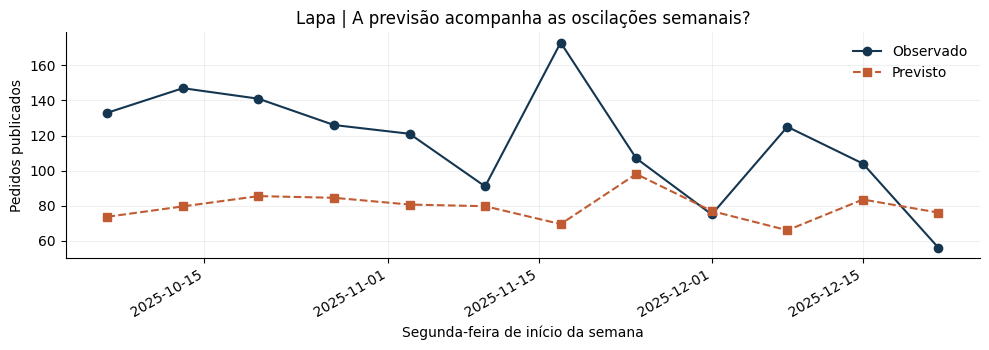

Maior erro absoluto: LAPA, 17/11/2025. Observado: 173; previsto: 69.5.


In [4]:
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
lapa = teste.loc[teste.distrito.eq("LAPA")].sort_values("semana")
fig, ax = plt.subplots()
ax.plot(lapa.semana, lapa.pedidos, "o-", color="#143650", label="Observado")
ax.plot(lapa.semana, lapa.volume_previsto, "s--", color="#c05b32", label="Previsto")
ax.set(title="Lapa | A previsão acompanha as oscilações semanais?", ylabel="Pedidos publicados",
       xlabel="Segunda-feira de início da semana")
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
erros = (teste.volume_previsto - teste.pedidos).abs()
pior = teste.loc[erros.idxmax()]
print(f"Maior erro absoluto: {pior.distrito}, {pior.semana:%d/%m/%Y}. "
      f"Observado: {pior.pedidos}; previsto: {pior.volume_previsto:.1f}.")

## 4. Regressão logística | risco de alta demanda

O modelo estima a probabilidade de cruzar o limite de pedidos aprendido no treino. Para classificar todos os distritos, escolhemos na validação o corte que maximiza F1 em uma grade definida previamente de 0,10 a 0,90. Em caso de empate usamos o maior corte, que reduz a quantidade de alertas. A regra das três vistorias da próxima seção usa a ordenação das probabilidades.

Corte escolhido na validação: 0.25


,Precisão,Recall,F1
Regressão logística,0.520,0.868,0.650
Média móvel ≥ limite,0.653,0.666,0.659


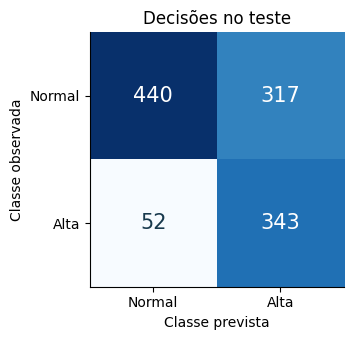

Foram **343 alertas corretos** e **317 alertas falsos**. Outras **52 semanas-distrito de alta demanda** ficaram sem alerta. A equipe pode usar a precisão para estimar visitas improdutivas e o recall para acompanhar quantos picos de reclamação escapam à triagem.

In [5]:
logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logistica.fit(treino[atributos], alta(treino))
p_val = logistica.predict_proba(validacao[atributos])[:, 1]
grade = np.round(np.arange(.10, .91, .05), 2)
corte = max(grade, key=lambda v: (f1_score(alta(validacao), p_val >= v), v))
teste["prob_alta"] = logistica.predict_proba(teste[atributos])[:, 1]
real = alta(teste)
alerta = (teste.prob_alta >= corte).astype(int)
matriz = confusion_matrix(real, alerta, labels=[0,1])
vn, fp, fn, vp = matriz.ravel()
def indicadores(previsto):
    return [precision_score(real, previsto, zero_division=0), recall_score(real, previsto),
            f1_score(real, previsto)]
desempenho = pd.DataFrame([indicadores(alerta), indicadores(teste.media_4 >= limite)],
                   index=["Regressão logística","Média móvel ≥ limite"],
                   columns=["Precisão","Recall","F1"])
print(f"Corte escolhido na validação: {corte:.2f}")
display(desempenho.round(3))
fig, ax = plt.subplots(figsize=(5.2, 3.5))
ax.imshow(matriz, cmap="Blues")
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(matriz[i,j]), ha="center", va="center", fontsize=15,
                color="white" if matriz[i,j] > matriz.max()/2 else "#18394d")
ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["Normal","Alta"], yticklabels=["Normal","Alta"],
       xlabel="Classe prevista", ylabel="Classe observada", title="Decisões no teste")
plt.tight_layout()
plt.show()
display(Markdown(f"Foram **{vp} alertas corretos** e **{fp} alertas falsos**. "
    f"Outras **{fn} semanas-distrito de alta demanda** ficaram sem alerta. "
    f"A equipe pode usar a precisão para estimar visitas improdutivas e o recall "
    f"para acompanhar quantos picos de reclamação escapam à triagem."))

## 5. Que decisão muda com três vistorias por semana?

Ordenamos os 96 distritos pela probabilidade prevista e escolhemos três por semana, com desempate alfabético. Repetimos o exercício com a média móvel. Ambas as regras usam exatamente o mesmo orçamento. Uma vistoria é considerada bem direcionada quando o distrito selecionado registra alta demanda na semana. Trata-se de um indicador substituto para testar a triagem.

In [6]:
def fila(coluna):
    return (teste.sort_values(["semana", coluna, "distrito"], ascending=[True,False,True])
                .groupby("semana", sort=True).head(3))
prioridade = fila("prob_alta")
def desempenho_fila(f):
    assert f.groupby("semana").size().eq(3).all(), "Cada semana deve ter três vagas."
    acertos = int(alta(f).sum())
    return [len(f), acertos, acertos / len(f), acertos / real.sum(), f.distrito.nunique()]
politicas = pd.DataFrame([desempenho_fila(prioridade), desempenho_fila(fila("media_4"))],
                         index=["Probabilidade logística", "Média de 4 semanas"],
                         columns=["Vagas","Altas encontradas","Acerto nas vagas",
                                  "Cobertura de todas as altas","Distritos distintos"])
display(politicas.round(3))
ultima = prioridade.loc[prioridade.semana.eq(prioridade.semana.max()),
                         ["semana","distrito","volume_previsto","prob_alta","pedidos"]]
display(ultima.round(3))
acertos = int(alta(prioridade).sum())
dif = acertos - int(alta(fila("media_4")).sum())
display(Markdown(f"Em **{len(prioridade)} vagas** ao longo de **{teste.semana.nunique()} semanas**, "
    f"a fila logística apontou **{acertos}** casos de alta e passou por **{prioridade.distrito.nunique()}** "
    f"distritos. A diferença foi de **{dif:+d} acertos** frente à média móvel. "
    f"Com essa capacidade foi possível cobrir **{acertos / real.sum():.1%}** das altas observadas. "
    "A prefeitura pode testar uma das vagas em rodízio, reservando as demais para o ranking, "
    "e comparar a cobertura dos distritos e os problemas confirmados por visita."))

,Vagas,Altas encontradas,Acerto nas vagas,Cobertura de todas as altas,Distritos distintos
Probabilidade logística,36,29,0.806,0.073,4
Média de 4 semanas,36,36,1.000,0.091,6


,semana,distrito,volume_previsto,prob_alta,pedidos
2447,2025-12-22,LAPA,76.051,1.000,56
1886,2025-12-22,JABAQUARA,27.265,1.000,19
3569,2025-12-22,SANTA CECILIA,13.609,0.987,13


Em **36 vagas** ao longo de **12 semanas**, a fila logística apontou **29** casos de alta e passou por **4** distritos. A diferença foi de **-7 acertos** frente à média móvel. Com essa capacidade foi possível cobrir **7.3%** das altas observadas. A prefeitura pode testar uma das vagas em rodízio, reservando as demais para o ranking, e comparar a cobertura dos distritos e os problemas confirmados por visita.

### Recomendação para um piloto

1. Na segunda-feira, a supervisão consulta a previsão de volume para organizar o tamanho da vistoria e a probabilidade de alta para selecionar os locais. A previsão orienta a inspeção; a confirmação em campo orienta a intervenção.
2. Antes de implantar a regra, comparar seus acertos com a média móvel. Empate ou queda no teste favorecem manter a regra simples como referência operacional. Avaliar o custo de cada **falso positivo** em deslocamento e o de cada **falso negativo** em demora para perceber a falha. Uma vistoria em um distrito classificado como normal ainda pode encontrar sujeira.
3. Durante um piloto, registrar vistorias concluídas, falhas confirmadas e tempo até correção. Comparar com territórios ou períodos de referência e acompanhar a cobertura dos distritos com baixa participação no SP156. A métrica de impacto para o cidadão é o tempo até a correção de uma falha confirmada. O histórico disponível mede apenas o desempenho da triagem.

### Alcance e limitações

O volume mede reclamações publicadas e depende da disposição e do acesso para registrar um pedido. Distritos com mais população ou com registros concentrados podem dominar a fila. O painel cobre um ano e o teste atravessa o último trimestre, sujeito a mudanças operacionais e efeitos de fim de ano. A linear tende a suavizar picos. Como os arquivos oficiais são trimestrais, uma operação semanal dependeria de acesso tempestivo às contagens agregadas. O estudo simula essa disponibilidade retrospectivamente. A validade do protótipo para outras cidades ou anos precisa ser testada novamente.

**Reprodução.** Extrair o ZIP, manter o CSV ao lado do notebook e executar todas as células na ordem. Ambiente de referência: Python 3.13, pandas 2.2, NumPy 2.2, scikit-learn 1.6 e Matplotlib 3.10. O preparo da base municipal está documentado no README e no script de agregação. O teste usa cortes cronológicos determinísticos.

### Decisão para o território

**Usar a média das quatro semanas anteriores para as três vagas de vistoria no piloto.** Ela encontrou alta demanda nas 36 vagas do teste, contra 29 da logística, e passou por seis distritos, contra quatro. Para alertas de acompanhamento de baixo custo, a logística alcançou 86,8% das altas, mas gerou 317 falsos alertas. Telefonar para verificar uma ocorrência e deslocar uma equipe têm custos diferentes. O corte de 0,25 é defensável para triagem remota e precisa de nova validação antes de autorizar deslocamentos.

**Dimensionar com margem nos picos.** Em 17 de novembro, a Lapa registrou 173 pedidos e a linear estimou 69,5. A pequena vantagem da linear em MAE veio acompanhada de RMSE maior que o da média móvel. Em uma semana fora do padrão, a supervisão deve consultar os registros locais antes de dimensionar a equipe. Os 36 acertos da referência ocorreram em uma única janela histórica; acompanhe esse indicador por ciclo no piloto.

**Conexão com Database Design.** `DEMANDA_SEMANAL` guarda pedidos publicados por distrito e segunda-feira. `PREVISAO_SEMANAL` armazena as duas saídas do modelo e o limite que definiu alta demanda. O DML reproduz um subconjunto das observações e das previsões deste teste.